# Experiment 13: False-Alarm-Controlled Embedding-Level Drift Detection

## 1. Research Objective

This experiment investigates the trade-off between false-alarm frequency and drift-detection sensitivity in embedding-level distribution-shift detectors.

Previous experiments identified false alarms in unchanged control streams. Experiment 13 will evaluate whether a more rigorous threshold-calibration and evaluation protocol can improve false-alarm reliability while preserving sensitivity to controlled distribution shifts.

## 2. Research Questions

1. How frequently do the existing detectors raise alarms on unchanged control data?
2. Can threshold calibration control the false-alarm rate on independent control data?
3. What effect does stricter false-alarm control have on detection sensitivity?
4. How consistent are these findings across repeated random seeds?

## 3. Experimental Scope

The experiment will compare embedding-level drift detectors under unchanged control conditions and controlled positive-drift conditions. Evaluation will use fixed, documented random seeds and separate calibration and evaluation data wherever the dataset permits.

## 4. Reporting Principles

Detection rate, false-alarm rate, and their uncertainty will be reported separately. Results will not be interpreted as evidence of real-world biometric recognition accuracy, demographic fairness, or deployment readiness.

All experimental parameters, random seeds, outputs, and limitations will be documented for reproducibility.

In [1]:
# Experiment 13: Environment setup

import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 202613
np.random.seed(SEED)

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Random seed:", SEED)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy version: 2.1.3
Pandas version: 2.2.3
Random seed: 202613


In [8]:
# Experiment 13 — Experimental Configuration

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 202613

CONFIG = {
    "experiment": 13,
    "random_seed": SEED,
    "n_seeds": 20,
    "embedding_dimension": 64,
    "reference_samples": 1000,
    "calibration_windows": 200,
    "control_windows": 500,
    "evaluation_windows_per_condition": 500,
    "window_size": 20,
    "target_false_alarm_rates": [0.01, 0.05, 0.10],
    "mean_shift_strengths": [0.0, 0.25, 0.5, 0.75, 1.0],
    "detectors": ["euclidean", "mahalanobis"],
}

print(json.dumps(CONFIG, indent=2))

{
  "experiment": 13,
  "random_seed": 202613,
  "n_seeds": 20,
  "embedding_dimension": 64,
  "reference_samples": 1000,
  "calibration_windows": 200,
  "control_windows": 500,
  "evaluation_windows_per_condition": 500,
  "window_size": 20,
  "target_false_alarm_rates": [
    0.01,
    0.05,
    0.1
  ],
  "mean_shift_strengths": [
    0.0,
    0.25,
    0.5,
    0.75,
    1.0
  ],
  "detectors": [
    "euclidean",
    "mahalanobis"
  ]
}


In [9]:
# Experiment 13 — Cell 3: Synthetic data generation

def generate_embedding_windows(
    rng,
    n_windows,
    window_size,
    dimension,
    mean_shift=0.0,
    covariance_scale=1.0,
):
    """
    Generate independent synthetic embedding windows.

    Each window contains window_size observations of dimension dimensions.
    mean_shift controls the magnitude of a shift in the first coordinate.
    covariance_scale controls the standard-deviation multiplier.
    """
    return rng.normal(
        loc=0.0,
        scale=covariance_scale,
        size=(n_windows, window_size, dimension),
    ) + np.array(
        [mean_shift] + [0.0] * (dimension - 1)
    )[None, None, :]


rng = np.random.default_rng(SEED)

reference = generate_embedding_windows(
    rng,
    n_windows=CONFIG["reference_samples"] // CONFIG["window_size"],
    window_size=CONFIG["window_size"],
    dimension=CONFIG["embedding_dimension"],
)

calibration = generate_embedding_windows(
    rng,
    n_windows=CONFIG["calibration_windows"],
    window_size=CONFIG["window_size"],
    dimension=CONFIG["embedding_dimension"],
)

control = generate_embedding_windows(
    rng,
    n_windows=CONFIG["control_windows"],
    window_size=CONFIG["window_size"],
    dimension=CONFIG["embedding_dimension"],
)

print("Reference windows:", reference.shape)
print("Calibration windows:", calibration.shape)
print("Control windows:", control.shape)
print("All values finite:", all(
    np.isfinite(x).all()
    for x in [reference, calibration, control]
))

Reference windows: (50, 20, 64)
Calibration windows: (200, 20, 64)
Control windows: (500, 20, 64)
All values finite: True


In [10]:
# Experiment 13 — Cell 4: Detector scoring

def fit_detector(reference_windows, ridge=0.01):
    """
    Fit Euclidean and regularized Mahalanobis detectors
    using reference-window means.
    """
    reference_means = reference_windows.mean(axis=1)

    center = reference_means.mean(axis=0)
    covariance = np.cov(reference_means, rowvar=False)

    covariance = (
        covariance
        + ridge * np.eye(covariance.shape[0])
    )

    inverse_covariance = np.linalg.pinv(covariance)

    return {
        "center": center,
        "inverse_covariance": inverse_covariance,
    }


def score_windows(windows, detector, method="euclidean"):
    """
    Score each window using its mean embedding.
    """
    window_means = windows.mean(axis=1)
    differences = window_means - detector["center"]

    if method == "euclidean":
        return np.linalg.norm(differences, axis=1)

    if method == "mahalanobis":
        distances_squared = np.einsum(
            "ni,ij,nj->n",
            differences,
            detector["inverse_covariance"],
            differences,
        )
        return np.sqrt(np.maximum(distances_squared, 0.0))

    raise ValueError(f"Unknown detector: {method}")


# Fit both detector configurations using reference data only.
fitted_detectors = {
    method: fit_detector(reference)
    for method in CONFIG["detectors"]
}

# Score independent calibration and control windows.
calibration_scores = {
    method: score_windows(calibration, fitted_detectors[method], method)
    for method in CONFIG["detectors"]
}

control_scores = {
    method: score_windows(control, fitted_detectors[method], method)
    for method in CONFIG["detectors"]
}

for method in CONFIG["detectors"]:
    print(f"\n{method.title()}")
    print("Calibration scores:", calibration_scores[method].shape)
    print("Control scores:", control_scores[method].shape)
    print("Calibration scores finite:",
          np.isfinite(calibration_scores[method]).all())
    print("Control scores finite:",
          np.isfinite(control_scores[method]).all())


Euclidean
Calibration scores: (200,)
Control scores: (500,)
Calibration scores finite: True
Control scores finite: True

Mahalanobis
Calibration scores: (200,)
Control scores: (500,)
Calibration scores finite: True
Control scores finite: True


In [11]:
# Experiment 13 — Cell 5: Threshold calibration and control evaluation

calibration_rows = []
control_rows = []

for method in CONFIG["detectors"]:
    scores_cal = calibration_scores[method]
    scores_control = control_scores[method]

    for target_fpr in CONFIG["target_false_alarm_rates"]:
        # Empirical upper-tail threshold.
        # Calibration data is not reused as control evaluation data.
        threshold = np.quantile(scores_cal, 1 - target_fpr)

        observed_fpr = np.mean(scores_control > threshold)

        calibration_rows.append({
            "detector": method,
            "target_false_alarm_rate": target_fpr,
            "threshold": threshold,
            "calibration_windows": len(scores_cal),
        })

        control_rows.append({
            "detector": method,
            "target_false_alarm_rate": target_fpr,
            "threshold": threshold,
            "control_windows": len(scores_control),
            "false_alarms": int(np.sum(scores_control > threshold)),
            "observed_false_alarm_rate": observed_fpr,
        })

calibration_df = pd.DataFrame(calibration_rows)
control_df = pd.DataFrame(control_rows)

print("CALIBRATION THRESHOLDS")
display(calibration_df.round(4))

print("\nINDEPENDENT CONTROL RESULTS")
display(control_df.round(4))

CALIBRATION THRESHOLDS


,detector,target_false_alarm_rate,threshold,calibration_windows
0,euclidean,0.01,2.1829,200
1,euclidean,0.05,2.0568,200
2,euclidean,0.10,1.9886,200
3,mahalanobis,0.01,15.1569,200
4,mahalanobis,0.05,13.9826,200
5,mahalanobis,0.10,13.6804,200



INDEPENDENT CONTROL RESULTS


,detector,target_false_alarm_rate,threshold,control_windows,false_alarms,observed_false_alarm_rate
0,euclidean,0.01,2.1829,500,6,0.012
1,euclidean,0.05,2.0568,500,31,0.062
2,euclidean,0.10,1.9886,500,61,0.122
3,mahalanobis,0.01,15.1569,500,8,0.016
4,mahalanobis,0.05,13.9826,500,36,0.072
5,mahalanobis,0.10,13.6804,500,55,0.110


In [12]:
# Experiment 13 — Cell 7: Positive-drift evaluation

evaluation_results = []

for shift in CONFIG["mean_shift_strengths"]:
    evaluation = generate_embedding_windows(
        rng,
        n_windows=CONFIG["evaluation_windows_per_condition"],
        window_size=CONFIG["window_size"],
        dimension=CONFIG["embedding_dimension"],
        mean_shift=shift,
    )

    for method in CONFIG["detectors"]:
        scores = score_windows(
            evaluation,
            fitted_detectors[method],
            method,
        )

        for target_fpr in CONFIG["target_false_alarm_rates"]:
            threshold = calibration_df.loc[
                (calibration_df["detector"] == method)
                & (calibration_df["target_false_alarm_rate"] == target_fpr),
                "threshold",
            ].iloc[0]

            evaluation_results.append({
                "detector": method,
                "mean_shift": shift,
                "target_false_alarm_rate": target_fpr,
                "threshold": threshold,
                "evaluation_windows": len(scores),
                "alarms": int(np.sum(scores > threshold)),
                "detection_rate": float(np.mean(scores > threshold)),
            })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.round(4)
    .sort_values(
        ["detector", "target_false_alarm_rate", "mean_shift"]
    )
    .reset_index(drop=True)
)

,detector,mean_shift,target_false_alarm_rate,threshold,evaluation_windows,alarms,detection_rate
0,euclidean,0.00,0.01,2.1829,500,4,0.008
1,euclidean,0.25,0.01,2.1829,500,7,0.014
2,euclidean,0.50,0.01,2.1829,500,22,0.044
3,euclidean,0.75,0.01,2.1829,500,40,0.080
4,euclidean,1.00,0.01,2.1829,500,115,0.230
5,euclidean,0.00,0.05,2.0568,500,18,0.036
6,euclidean,0.25,0.05,2.0568,500,35,0.070
7,euclidean,0.50,0.05,2.0568,500,59,0.118
8,euclidean,0.75,0.05,2.0568,500,118,0.236
9,euclidean,1.00,0.05,2.0568,500,247,0.494


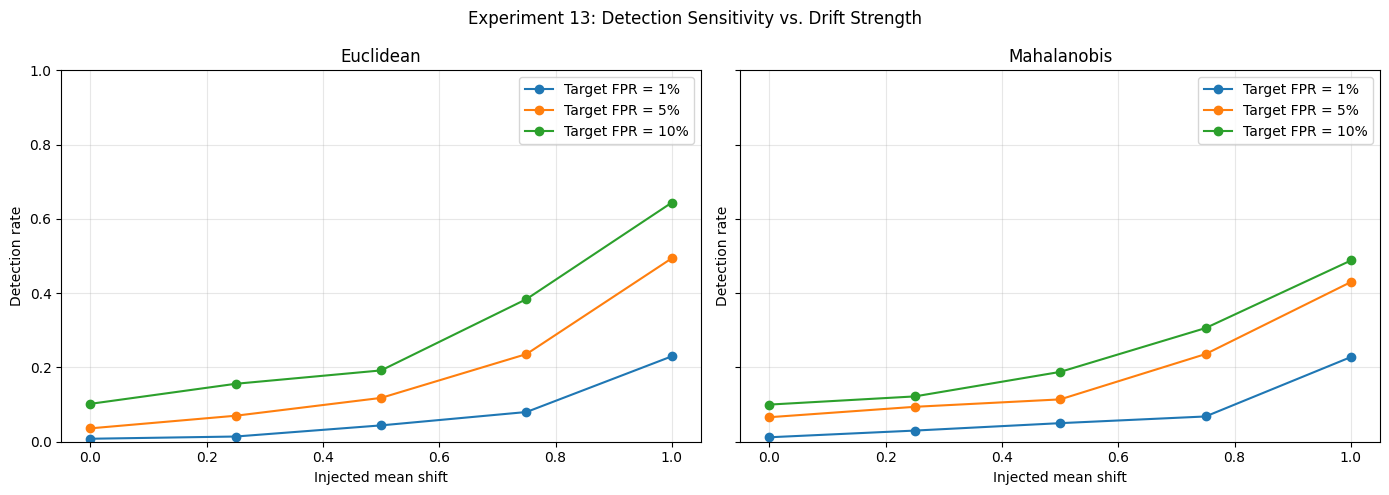

In [13]:
# Experiment 13 — Cell 8: Detection-rate plots

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, method in zip(axes, CONFIG["detectors"]):
    subset = evaluation_df[evaluation_df["detector"] == method]

    for target in CONFIG["target_false_alarm_rates"]:
        curve = subset[
            subset["target_false_alarm_rate"] == target
        ].sort_values("mean_shift")

        ax.plot(
            curve["mean_shift"],
            curve["detection_rate"],
            marker="o",
            label=f"Target FPR = {target:.0%}",
        )

    ax.set_title(method.title())
    ax.set_xlabel("Injected mean shift")
    ax.set_ylabel("Detection rate")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Experiment 13: Detection Sensitivity vs. Drift Strength")
plt.tight_layout()
plt.show()

In [14]:
# Experiment 13 — Multi-seed evaluation

N_SEEDS = 20
SEED_BASE = 202613

multi_seed_rows = []

for seed in range(SEED_BASE, SEED_BASE + N_SEEDS):
    seed_rng = np.random.default_rng(seed)

    # Independent datasets for this seed
    ref = generate_embedding_windows(
        seed_rng, 50, 20, CONFIG["embedding_dimension"]
    )
    cal = generate_embedding_windows(
        seed_rng, 200, 20, CONFIG["embedding_dimension"]
    )
    ctrl = generate_embedding_windows(
        seed_rng, 500, 20, CONFIG["embedding_dimension"]
    )

    # Fit detectors using reference data only
    seed_detectors = {
        method: fit_detector(ref)
        for method in CONFIG["detectors"]
    }

    cal_scores = {
        method: score_windows(cal, seed_detectors[method], method)
        for method in CONFIG["detectors"]
    }
    ctrl_scores = {
        method: score_windows(ctrl, seed_detectors[method], method)
        for method in CONFIG["detectors"]
    }

    # Evaluate false alarms and sensitivity
    for method in CONFIG["detectors"]:
        for target in CONFIG["target_false_alarm_rates"]:
            threshold = np.quantile(
                cal_scores[method], 1 - target
            )

            control_fpr = np.mean(ctrl_scores[method] > threshold)

            multi_seed_rows.append({
                "seed": seed,
                "detector": method,
                "target_fpr": target,
                "mean_shift": 0.0,
                "observed_fpr": control_fpr,
                "detection_rate": control_fpr,
                "threshold": threshold,
            })

            for shift in CONFIG["mean_shift_strengths"]:
                eval_data = generate_embedding_windows(
                    seed_rng,
                    500,
                    20,
                    CONFIG["embedding_dimension"],
                    mean_shift=shift,
                )

                eval_scores = score_windows(
                    eval_data, seed_detectors[method], method
                )

                detection_rate = np.mean(eval_scores > threshold)

                multi_seed_rows.append({
                    "seed": seed,
                    "detector": method,
                    "target_fpr": target,
                    "mean_shift": shift,
                    "observed_fpr": control_fpr,
                    "detection_rate": detection_rate,
                    "threshold": threshold,
                })

multi_seed_df = pd.DataFrame(multi_seed_rows)

print("Rows:", len(multi_seed_df))
print("Seeds:", multi_seed_df["seed"].nunique())
print("All detection rates finite:",
      np.isfinite(multi_seed_df["detection_rate"]).all())

display(multi_seed_df.head(10))

Rows: 720
Seeds: 20
All detection rates finite: True


,seed,detector,target_fpr,mean_shift,observed_fpr,detection_rate,threshold
0,202613,euclidean,0.01,0.00,0.012,0.012,2.182925
1,202613,euclidean,0.01,0.00,0.012,0.008,2.182925
2,202613,euclidean,0.01,0.25,0.012,0.014,2.182925
3,202613,euclidean,0.01,0.50,0.012,0.044,2.182925
4,202613,euclidean,0.01,0.75,0.012,0.080,2.182925
5,202613,euclidean,0.01,1.00,0.012,0.230,2.182925
6,202613,euclidean,0.05,0.00,0.062,0.062,2.056774
7,202613,euclidean,0.05,0.00,0.062,0.052,2.056774
8,202613,euclidean,0.05,0.25,0.062,0.082,2.056774
9,202613,euclidean,0.05,0.50,0.062,0.132,2.056774


In [15]:
# Experiment 13 — Corrected paired multi-seed evaluation

N_SEEDS = 20
SEED_BASE = 202613

corrected_rows = []

for seed in range(SEED_BASE, SEED_BASE + N_SEEDS):
    seed_rng = np.random.default_rng(seed)

    # 1. Generate independent datasets for this seed
    ref = generate_embedding_windows(
        seed_rng, 50, 20, CONFIG["embedding_dimension"]
    )
    cal = generate_embedding_windows(
        seed_rng, 200, 20, CONFIG["embedding_dimension"]
    )
    ctrl = generate_embedding_windows(
        seed_rng, 500, 20, CONFIG["embedding_dimension"]
    )

    # 2. Fit detectors on the same reference data
    models = {
        method: fit_detector(ref)
        for method in CONFIG["detectors"]
    }

    # 3. Score calibration and control data
    cal_scores = {
        method: score_windows(cal, models[method], method)
        for method in CONFIG["detectors"]
    }

    ctrl_scores = {
        method: score_windows(ctrl, models[method], method)
        for method in CONFIG["detectors"]
    }

    # 4. Generate each evaluation condition ONCE per seed.
    # Both detectors use the same samples for every shift.
    eval_data_by_shift = {
        shift: generate_embedding_windows(
            seed_rng,
            500,
            20,
            CONFIG["embedding_dimension"],
            mean_shift=shift,
        )
        for shift in CONFIG["mean_shift_strengths"]
    }

    eval_scores_by_method = {
        method: {
            shift: score_windows(
                eval_data_by_shift[shift],
                models[method],
                method,
            )
            for shift in CONFIG["mean_shift_strengths"]
        }
        for method in CONFIG["detectors"]
    }

    # 5. Apply thresholds calibrated exclusively on calibration data
    for method in CONFIG["detectors"]:
        for target in CONFIG["target_false_alarm_rates"]:

            threshold = np.quantile(
                cal_scores[method], 1 - target
            )

            control_fpr = float(
                np.mean(ctrl_scores[method] > threshold)
            )

            corrected_rows.append({
                "seed": seed,
                "detector": method,
                "target_fpr": target,
                "condition_type": "control",
                "mean_shift": np.nan,
                "threshold": threshold,
                "n_windows": len(ctrl_scores[method]),
                "alarms": int(
                    np.sum(ctrl_scores[method] > threshold)
                ),
                "rate": control_fpr,
            })

            # Positive and zero-shift evaluation conditions
            for shift in CONFIG["mean_shift_strengths"]:
                scores = eval_scores_by_method[method][shift]
                alarms = int(np.sum(scores > threshold))

                corrected_rows.append({
                    "seed": seed,
                    "detector": method,
                    "target_fpr": target,
                    "condition_type": "evaluation",
                    "mean_shift": shift,
                    "threshold": threshold,
                    "n_windows": len(scores),
                    "alarms": alarms,
                    "rate": float(alarms / len(scores)),
                })

corrected_df = pd.DataFrame(corrected_rows)

print("Total rows:", len(corrected_df))
print("Unique seeds:", corrected_df["seed"].nunique())
print("Detectors:", sorted(corrected_df["detector"].unique()))
print("Condition types:",
      sorted(corrected_df["condition_type"].unique()))
print("All rates finite:",
      np.isfinite(corrected_df["rate"]).all())

assert len(corrected_df) == 720
assert corrected_df["seed"].nunique() == 20
assert corrected_df["rate"].between(0, 1).all()

display(corrected_df.head(12))

Total rows: 720
Unique seeds: 20
Detectors: ['euclidean', 'mahalanobis']
Condition types: ['control', 'evaluation']
All rates finite: True


,seed,detector,target_fpr,condition_type,mean_shift,threshold,n_windows,alarms,rate
0,202613,euclidean,0.01,control,NaN,2.182925,500,6,0.012
1,202613,euclidean,0.01,evaluation,0.00,2.182925,500,4,0.008
2,202613,euclidean,0.01,evaluation,0.25,2.182925,500,7,0.014
3,202613,euclidean,0.01,evaluation,0.50,2.182925,500,22,0.044
4,202613,euclidean,0.01,evaluation,0.75,2.182925,500,40,0.080
5,202613,euclidean,0.01,evaluation,1.00,2.182925,500,115,0.230
6,202613,euclidean,0.05,control,NaN,2.056774,500,31,0.062
7,202613,euclidean,0.05,evaluation,0.00,2.056774,500,18,0.036
8,202613,euclidean,0.05,evaluation,0.25,2.056774,500,35,0.070
9,202613,euclidean,0.05,evaluation,0.50,2.056774,500,59,0.118


In [16]:
# Experiment 13 — Cell 12: Multi-seed summary

# Control false-alarm rates across seeds
control_summary = (
    corrected_df[corrected_df["condition_type"] == "control"]
    .groupby(["detector", "target_fpr"])["rate"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .rename(columns={
        "mean": "mean_control_fpr",
        "std": "sd_control_fpr",
        "min": "min_control_fpr",
        "max": "max_control_fpr",
    })
)

# Detection rates across seeds, by drift strength
detection_summary = (
    corrected_df[corrected_df["condition_type"] == "evaluation"]
    .groupby(["detector", "target_fpr", "mean_shift"])["rate"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .rename(columns={
        "mean": "mean_detection_rate",
        "std": "sd_detection_rate",
        "min": "min_detection_rate",
        "max": "max_detection_rate",
    })
)

print("CONTROL FALSE-ALARM SUMMARY")
display(control_summary.round(4))

print("DETECTION SENSITIVITY SUMMARY")
display(detection_summary.round(4))

CONTROL FALSE-ALARM SUMMARY


,detector,target_fpr,mean_control_fpr,sd_control_fpr,min_control_fpr,max_control_fpr
0,euclidean,0.01,0.0136,0.0117,0.000,0.046
1,euclidean,0.05,0.0565,0.0191,0.020,0.090
2,euclidean,0.10,0.1077,0.0254,0.054,0.152
3,mahalanobis,0.01,0.0152,0.0093,0.002,0.042
4,mahalanobis,0.05,0.0513,0.0173,0.020,0.082
5,mahalanobis,0.10,0.0997,0.0222,0.070,0.154


DETECTION SENSITIVITY SUMMARY


,detector,target_fpr,mean_shift,mean_detection_rate,sd_detection_rate,min_detection_rate,max_detection_rate
0,euclidean,0.01,0.00,0.0127,0.0106,0.000,0.036
1,euclidean,0.01,0.25,0.0202,0.0147,0.000,0.058
2,euclidean,0.01,0.50,0.0409,0.0253,0.002,0.102
3,euclidean,0.01,0.75,0.0981,0.0517,0.026,0.232
4,euclidean,0.01,1.00,0.2573,0.0879,0.126,0.460
5,euclidean,0.05,0.00,0.0504,0.0209,0.020,0.096
6,euclidean,0.05,0.25,0.0694,0.0258,0.028,0.124
7,euclidean,0.05,0.50,0.1220,0.0289,0.076,0.190
8,euclidean,0.05,0.75,0.2411,0.0584,0.144,0.358
9,euclidean,0.05,1.00,0.4748,0.0678,0.370,0.612


In [17]:
# Experiment 13 — Step 13: Confidence intervals across seeds

from scipy.stats import t

def summarize_with_ci(data, group_columns):
    grouped = data.groupby(group_columns)["rate"]

    summary = grouped.agg(
        mean="mean",
        sd="std",
        n="count"
    ).reset_index()

    summary["se"] = summary["sd"] / np.sqrt(summary["n"])

    critical = t.ppf(
        0.975,
        df=summary["n"] - 1
    )

    summary["ci95_lower"] = (
        summary["mean"] - critical * summary["se"]
    ).clip(0, 1)

    summary["ci95_upper"] = (
        summary["mean"] + critical * summary["se"]
    ).clip(0, 1)

    return summary


control_ci = summarize_with_ci(
    corrected_df[
        corrected_df["condition_type"] == "control"
    ],
    ["detector", "target_fpr"]
)

detection_ci = summarize_with_ci(
    corrected_df[
        corrected_df["condition_type"] == "evaluation"
    ],
    ["detector", "target_fpr", "mean_shift"]
)

print("CONTROL FPR — 95% CI")
display(control_ci.round(4))

print("DETECTION RATE — 95% CI")
display(detection_ci.round(4))

CONTROL FPR — 95% CI


,detector,target_fpr,mean,sd,n,se,ci95_lower,ci95_upper
0,euclidean,0.01,0.0136,0.0117,20,0.0026,0.0081,0.0191
1,euclidean,0.05,0.0565,0.0191,20,0.0043,0.0476,0.0654
2,euclidean,0.10,0.1077,0.0254,20,0.0057,0.0958,0.1196
3,mahalanobis,0.01,0.0152,0.0093,20,0.0021,0.0109,0.0195
4,mahalanobis,0.05,0.0513,0.0173,20,0.0039,0.0432,0.0594
5,mahalanobis,0.10,0.0997,0.0222,20,0.0050,0.0893,0.1101


DETECTION RATE — 95% CI


,detector,target_fpr,mean_shift,mean,sd,n,se,ci95_lower,ci95_upper
0,euclidean,0.01,0.00,0.0127,0.0106,20,0.0024,0.0077,0.0177
1,euclidean,0.01,0.25,0.0202,0.0147,20,0.0033,0.0133,0.0271
2,euclidean,0.01,0.50,0.0409,0.0253,20,0.0057,0.0291,0.0527
3,euclidean,0.01,0.75,0.0981,0.0517,20,0.0116,0.0739,0.1223
4,euclidean,0.01,1.00,0.2573,0.0879,20,0.0197,0.2162,0.2984
5,euclidean,0.05,0.00,0.0504,0.0209,20,0.0047,0.0406,0.0602
6,euclidean,0.05,0.25,0.0694,0.0258,20,0.0058,0.0573,0.0815
7,euclidean,0.05,0.50,0.1220,0.0289,20,0.0065,0.1085,0.1355
8,euclidean,0.05,0.75,0.2411,0.0584,20,0.0131,0.2138,0.2684
9,euclidean,0.05,1.00,0.4748,0.0678,20,0.0152,0.4431,0.5065


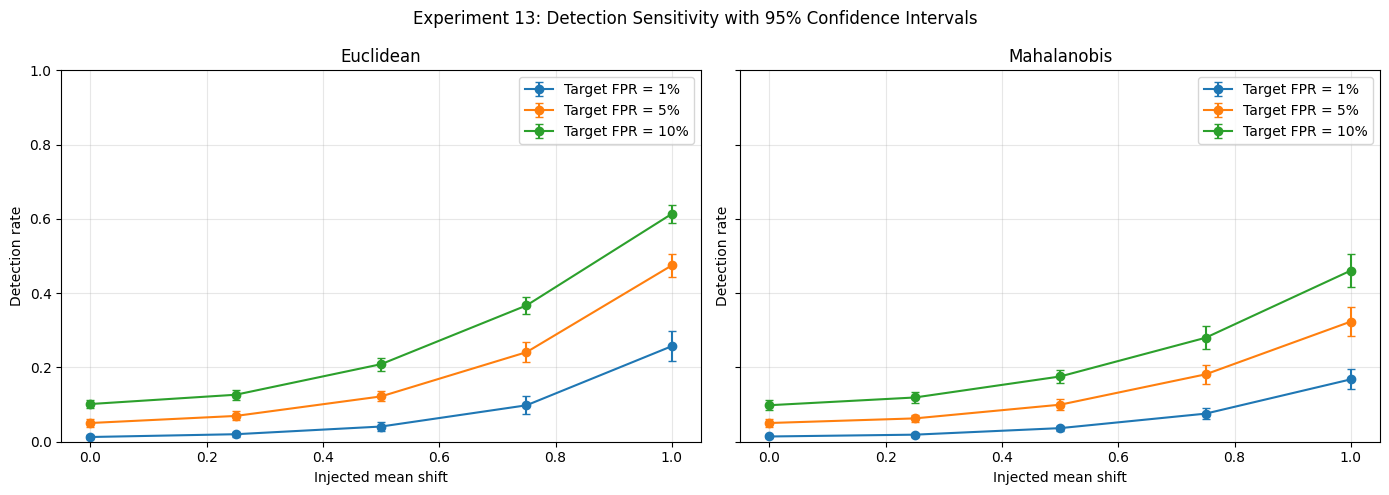

Saved: experiment13_detection_ci.png


In [18]:
# Experiment 13 — Final plots with 95% confidence intervals

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, method in zip(axes, CONFIG["detectors"]):
    for target in CONFIG["target_false_alarm_rates"]:
        curve = detection_ci[
            (detection_ci["detector"] == method)
            & (detection_ci["target_fpr"] == target)
        ].sort_values("mean_shift")

        ax.errorbar(
            curve["mean_shift"],
            curve["mean"],
            yerr=[
                curve["mean"] - curve["ci95_lower"],
                curve["ci95_upper"] - curve["mean"],
            ],
            marker="o",
            capsize=3,
            label=f"Target FPR = {target:.0%}",
        )

    ax.set_title(method.title())
    ax.set_xlabel("Injected mean shift")
    ax.set_ylabel("Detection rate")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Experiment 13: Detection Sensitivity with 95% Confidence Intervals"
)
plt.tight_layout()
plt.savefig("experiment13_detection_ci.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: experiment13_detection_ci.png")

In [19]:
from pathlib import Path

OUTPUT_DIR = Path("experiment13_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

corrected_df.to_csv(
    OUTPUT_DIR / "experiment13_trial_results.csv",
    index=False,
)

control_ci.to_csv(
    OUTPUT_DIR / "experiment13_control_fpr_summary.csv",
    index=False,
)

detection_ci.to_csv(
    OUTPUT_DIR / "experiment13_detection_summary.csv",
    index=False,
)

calibration_df.to_csv(
    OUTPUT_DIR / "experiment13_single_seed_calibration.csv",
    index=False,
)

control_df.to_csv(
    OUTPUT_DIR / "experiment13_single_seed_control.csv",
    index=False,
)

print("Exported files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Exported files:
experiment13_control_fpr_summary.csv: 742 bytes
experiment13_detection_summary.csv: 3,490 bytes
experiment13_single_seed_calibration.csv: 294 bytes
experiment13_single_seed_control.csv: 380 bytes
experiment13_trial_results.csv: 49,452 bytes


In [20]:
# Experiment 13 — Step 16: Generate reproducible report

from pathlib import Path

OUTPUT_DIR = Path("experiment13_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def markdown_table(df):
    return df.to_markdown(index=False, floatfmt=".4f")

report = f"""# Experiment 13: False-Alarm-Controlled Embedding-Level Drift Detection

## 1. Objective

Evaluate the trade-off between false-alarm frequency and detection sensitivity
for Euclidean and regularised Mahalanobis embedding-level drift detectors
under controlled synthetic distribution shifts.

## 2. Experimental Configuration

- Random seeds: 20 consecutive seeds beginning at 202613
- Embedding dimension: 64
- Reference windows: 50 per seed, each containing 20 observations
- Calibration windows: 200 per seed
- Independent control windows: 500 per seed
- Evaluation windows: 500 per seed and shift condition
- Mean-shift strengths: 0.00, 0.25, 0.50, 0.75, 1.00
- Nominal calibration false-alarm targets: 1%, 5%, 10%
- Detectors: Euclidean and regularised Mahalanobis
- Covariance ridge parameter: 0.01

## 3. Methodology

Each seed generated separate reference, calibration, control, and evaluation
datasets. Detector parameters were fitted using reference data. Thresholds
were estimated using calibration scores only. Control and evaluation datasets
were scored without being used to fit thresholds.

Within each seed and shift condition, both detectors used the same evaluation
samples. The positive-shift conditions applied an additive shift to the first
embedding coordinate.

The evaluation unit was an embedding window. An alarm was counted when its
distance score exceeded the calibrated threshold.

## 4. Control False-Alarm Results

{markdown_table(control_ci)}

## 5. Detection Sensitivity Results

{markdown_table(detection_ci)}

## 6. Interpretation

The observed mean control false-alarm rates were generally close to the
nominal targets, but individual-seed variability was substantial at the
1% target.

Detection rates increased as the injected mean shift increased. Across the
tested conditions, Euclidean generally achieved higher detection rates than
Mahalanobis, particularly at stronger shifts. This is a finding for this
specific synthetic setup and does not establish universal detector superiority.

At the 5% target and shift strength 1.00, the mean detection rates were
47.48% for Euclidean and 32.36% for Mahalanobis. At the 10% target, they
were 61.36% and 46.10%, respectively.

The confidence intervals describe variability across 20 seed-level results.
They do not establish performance on real biometric identities or deployed
systems.

## 7. Limitations

1. All observations were synthetic Gaussian vectors, not real biometric embeddings.
2. The injected drift was an additive shift in one coordinate.
3. The experiment used independent windows rather than a temporally dependent stream.
4. Detection delay and sequential alarm behaviour were not evaluated.
5. No demographic fairness, biometric recognition accuracy, or bias mitigation
   was evaluated.
6. Results depend on the selected dimension, covariance regularisation,
   sample sizes, and threshold calibration method.
7. The evaluation does not establish identity-disjoint or real-world
   generalisation.

## 8. Reproducibility

- Main trial results: `experiment13_trial_results.csv`
- Control summary and confidence intervals: `experiment13_control_fpr_summary.csv`
- Detection summary and confidence intervals: `experiment13_detection_summary.csv`
- Initial calibration results: `experiment13_single_seed_calibration.csv`
- Initial control results: `experiment13_single_seed_control.csv`
- Detection plot: `experiment13_detection_ci.png`

The experiment uses NumPy random generators with documented seeds. The
reported results should be regenerated from the saved notebook before
publication.

## 9. Conclusion

This synthetic study demonstrates a measurable trade-off between nominal
false-alarm targets and detection sensitivity. The results motivate further
evaluation using real embeddings, multiple drift mechanisms, and temporally
structured streams. They should be treated as preliminary methodological
evidence rather than real-world biometric validation.
"""

report_path = OUTPUT_DIR / "Experiment_13_Reproducible_Report.md"
report_path.write_text(report, encoding="utf-8")

print("Report saved:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")
print("\nReport preview:\n")
print(report[:1500])

Report saved: experiment13_outputs/Experiment_13_Reproducible_Report.md
Report size: 8143 bytes

Report preview:

# Experiment 13: False-Alarm-Controlled Embedding-Level Drift Detection

## 1. Objective

Evaluate the trade-off between false-alarm frequency and detection sensitivity
for Euclidean and regularised Mahalanobis embedding-level drift detectors
under controlled synthetic distribution shifts.

## 2. Experimental Configuration

- Random seeds: 20 consecutive seeds beginning at 202613
- Embedding dimension: 64
- Reference windows: 50 per seed, each containing 20 observations
- Calibration windows: 200 per seed
- Independent control windows: 500 per seed
- Evaluation windows: 500 per seed and shift condition
- Mean-shift strengths: 0.00, 0.25, 0.50, 0.75, 1.00
- Nominal calibration false-alarm targets: 1%, 5%, 10%
- Detectors: Euclidean and regularised Mahalanobis
- Covariance ridge parameter: 0.01

## 3. Methodology

Each seed generated separate reference, calibration, control, 

In [21]:
from pathlib import Path

OUTPUT_DIR = Path("experiment13_outputs")

required_files = [
    "experiment13_trial_results.csv",
    "experiment13_control_fpr_summary.csv",
    "experiment13_detection_summary.csv",
    "experiment13_single_seed_calibration.csv",
    "experiment13_single_seed_control.csv",
    "Experiment_13_Reproducible_Report.md",
]

print("EXPERIMENT 13 ARTIFACT CHECK\n")

all_present = True

for filename in required_files:
    path = OUTPUT_DIR / filename
    exists = path.is_file()
    all_present &= exists

    print(
        f"{'OK' if exists else 'MISSING'}: "
        f"{filename}"
        + (f" ({path.stat().st_size:,} bytes)" if exists else "")
    )

plot_path = Path("experiment13_detection_ci.png")
print(
    f"\n{'OK' if plot_path.is_file() else 'MISSING'}: "
    f"{plot_path}"
)

print("\nAll required CSV/report files present:", all_present)

EXPERIMENT 13 ARTIFACT CHECK

OK: experiment13_trial_results.csv (49,452 bytes)
OK: experiment13_control_fpr_summary.csv (742 bytes)
OK: experiment13_detection_summary.csv (3,490 bytes)
OK: experiment13_single_seed_calibration.csv (294 bytes)
OK: experiment13_single_seed_control.csv (380 bytes)
OK: Experiment_13_Reproducible_Report.md (8,143 bytes)

OK: experiment13_detection_ci.png

All required CSV/report files present: True


In [22]:
# Experiment 13 — Package the final artifacts

from pathlib import Path
import shutil

OUTPUT_DIR = Path("experiment13_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Copy the final detection plot into the output folder
plot_source = Path("experiment13_detection_ci.png")
plot_destination = OUTPUT_DIR / "experiment13_detection_ci.png"

if plot_source.exists():
    shutil.copy2(plot_source, plot_destination)
else:
    raise FileNotFoundError(f"Missing plot: {plot_source}")

readme = """# Experiment 13 — False-Alarm-Controlled Embedding-Level Drift Detection

## Objective
Evaluate the trade-off between false-alarm frequency and detection sensitivity
for Euclidean and regularized Mahalanobis detectors under controlled synthetic shifts.

## Method
- 20 random seeds, starting at 202613
- 64-dimensional synthetic Gaussian embeddings
- 50 reference windows per seed
- 200 calibration windows per seed
- 500 independent control windows per seed
- 500 evaluation windows per shift condition
- Window size: 20 observations
- Mean shifts: 0.00, 0.25, 0.50, 0.75, 1.00
- Nominal false-alarm targets: 1%, 5%, 10%
- Covariance ridge parameter: 0.01

## Files
- `experiment13_trial_results.csv`: seed-level control and evaluation results
- `experiment13_control_fpr_summary.csv`: control false-alarm summary and 95% intervals
- `experiment13_detection_summary.csv`: detection sensitivity summary and 95% intervals
- `experiment13_single_seed_calibration.csv`: initial calibration thresholds
- `experiment13_single_seed_control.csv`: initial control evaluation
- `experiment13_detection_ci.png`: detection sensitivity plot with 95% intervals
- `Experiment_13_Reproducible_Report.md`: methodology, results, and limitations

## Main finding
Detection sensitivity increased with injected mean-shift strength. The Euclidean
detector generally achieved higher detection rates than the Mahalanobis detector
under this synthetic configuration. This does not establish universal superiority.

## Limitations
All data are synthetic Gaussian vectors. The experiment does not validate real
biometric embeddings, naturally occurring drift, identity-disjoint generalization,
demographic fairness, biometric recognition accuracy, or deployment readiness.
Windows are independent; sequential detection delay is not measured.

## Reproducibility
The notebook records the generation process and random seeds. Re-run the notebook
from a fresh runtime to verify that the saved results and figures can be regenerated.
"""

readme_path = OUTPUT_DIR / "README_Experiment_13.md"
readme_path.write_text(readme, encoding="utf-8")

print("Package contents:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Package contents:
Experiment_13_Reproducible_Report.md: 8,143 bytes
README_Experiment_13.md: 2,006 bytes
experiment13_control_fpr_summary.csv: 742 bytes
experiment13_detection_ci.png: 235,960 bytes
experiment13_detection_summary.csv: 3,490 bytes
experiment13_single_seed_calibration.csv: 294 bytes
experiment13_single_seed_control.csv: 380 bytes
experiment13_trial_results.csv: 49,452 bytes


In [23]:
from google.colab import files
import shutil

shutil.make_archive(
    "experiment13_outputs",
    "zip",
    root_dir="experiment13_outputs"
)

files.download("experiment13_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>